# 131 · Sim-to-real in miniature: visual domain randomization for a pixel policy

In [1]:
import os, time, json, numpy as np, torch, matplotlib.pyplot as plt
from vlacourse import TableTop, collect, show_images
from vlacourse import scene_dataset, collect_parallel
SCENE = "single"                    # TableTop scene tier (see vlacourse.SCENES)
from vlacourse.torch_data import TableTopDataset
from vlacourse.chunk_policies import FlowPolicy, train_policy, ChunkPolicy
from vlacourse.eval_suite import run_suite, SUITE

NOMINAL = scene_dataset(SCENE)
RANDOM = os.path.abspath(f"../data/tabletop_{SCENE}_visdr")
device = "cuda" if torch.cuda.is_available() else "cpu"
if device == "cuda":
    torch.cuda.set_per_process_memory_fraction(0.8)
os.makedirs("checkpoints", exist_ok=True)
H = 16

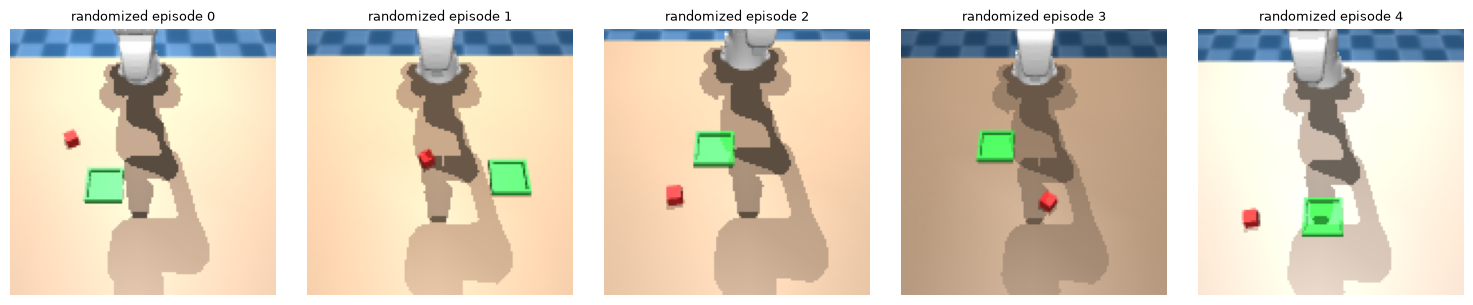

In [2]:
if not os.path.exists(os.path.join(RANDOM, "meta.json")):
    t0 = time.time(); collect_parallel(RANDOM, 500, seed=1, scene=SCENE, visual_randomization=True); print(f"collected in {time.time() - t0:.0f}s")
env_r = TableTop(scene=SCENE, cameras=("front",), image_size=(128, 128), visual_randomization=True, seed=0)
show_images([env_r.reset(seed=s)["images"]["front"] for s in range(5)], [f"randomized episode {s}" for s in range(5)], cols=5)

In [3]:
nets = {}
for name, data in [("nominal data", NOMINAL), ("visually randomized data", RANDOM)]:
    path = f"checkpoints/flow_{'dr' if 'visdr' in data else 'nominal'}.pt"
    ds = TableTopDataset(data, episodes=range(450), horizon=H)
    net = FlowPolicy(horizon=H)
    if os.path.exists(path):
        net.load_state_dict(torch.load(path, map_location=device)); net.to(device)
    else:
        t0 = time.time(); train_policy(net, ds, epochs=50, device=device); torch.save(net.state_dict(), path); print(f"{name}: trained in {time.time() - t0:.0f}s")
    nets[name] = (net.eval(), ds)

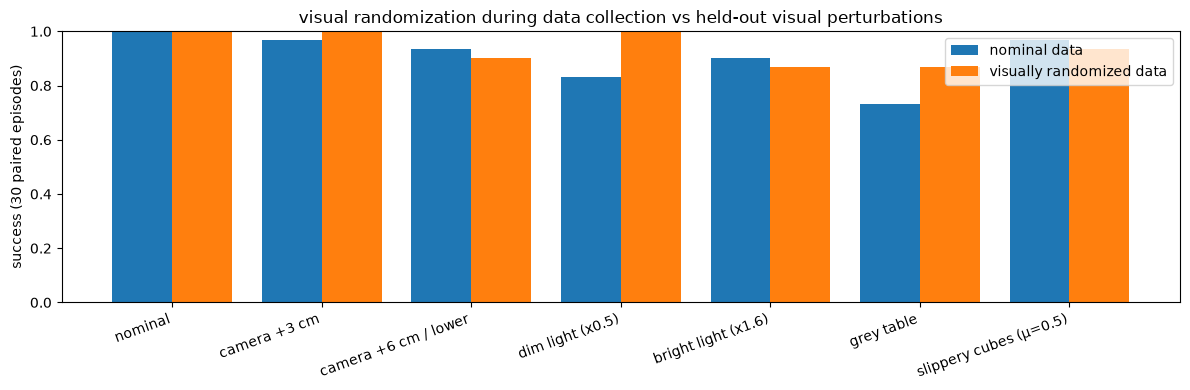

nominal data               nominal 1.00 | mean over visual perturbations 0.87 | worst 0.73
visually randomized data   nominal 1.00 | mean over visual perturbations 0.93 | worst 0.87


In [4]:
env = TableTop(scene=SCENE, cameras=("front", "wrist"), image_size=(128, 128), seed=0)
results = {name: run_suite(env, ChunkPolicy(net, ds, env, device, execute=8, nfe=4), n_episodes=30) for name, (net, ds) in nets.items()}
conds = [p.name for p in SUITE]
x = np.arange(len(conds)); w = 0.4
plt.figure(figsize=(12, 4))
for k, (name, res) in enumerate(results.items()):
    plt.bar(x + (k - 0.5) * w, [res[c]["success"] for c in conds], w, label=name)
plt.xticks(x, conds, rotation=20, ha="right"); plt.ylim(0, 1); plt.ylabel("success (30 paired episodes)"); plt.legend()
plt.title("visual randomization during data collection vs held-out visual perturbations"); plt.tight_layout(); plt.show()
for name, res in results.items():
    vis = [res[c]["success"] for c in conds if c not in ("nominal", "slippery cubes (μ=0.5)")]
    print(f"{name:26s} nominal {res['nominal']['success']:.2f} | mean over visual perturbations {np.mean(vis):.2f} | worst {min(vis):.2f}")
os.makedirs("results", exist_ok=True)
json.dump({n: {c: r[c]["success"] for c in conds} for n, r in results.items()}, open("results/visual_dr.json", "w"), indent=1)

### Watch it: the perturbation that hurt the nominal policy most
Both policies face the same visual change; only their training data differs.

In [5]:
from vlacourse import showcase as sc
from vlacourse.eval_suite import _restore_all
def perturbed(fn):
    return lambda e: (_restore_all(e), fn(e))
sfx = {p.name: p.apply_fn for p in SUITE}
worst = min(conds[1:], key=lambda c: results["nominal data"][c]["success"])
pols = {"trained on nominal data": ChunkPolicy(*nets["nominal data"], env, device, execute=8, nfe=4),
        "trained with visual randomization": ChunkPolicy(*nets["visually randomized data"], env, device, execute=8, nfe=4)}
sc.compare(env, pols, seed=200_001, on_reset=perturbed(sfx[worst]), footer=f"test condition: {worst}", title="131 nominal vs randomized training")
_restore_all(env)

131 nominal vs randomized training: trained on nominal data: success | trained with visual randomization: success
